# Analyse des réservations d'hôtels

Les données utilisées sont le fichier nettoyé `data/processed/hotels_propre.csv` (voir `02_nettoyage.ipynb`). Chaque analyse répond à une des questions métier du notebook 01.

In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)
sns.set_theme(style="whitegrid")

hotels = pd.read_csv(
    "../data/processed/hotels_propre.csv",
    parse_dates=["arrival_date", "reservation_status_date"],
)

hotels["hotel"] = hotels["hotel"].map({
    "City Hotel": "Hôtel de ville",
    "Resort Hotel": "Hôtel de villégiature",
})
hotels["deposit_type"] = hotels["deposit_type"].map({
    "No Deposit": "Sans dépôt",
    "Refundable": "Dépôt remboursable",
    "Non Refund": "Dépôt non remboursable",
})
hotels

,hotel,is_canceled,lead_time,arrival_date_week_number,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,arrival_date
0,Hôtel de villégiature,0,7,27,0,1,1,0,0,BB,...,0,Sans dépôt,0,0,Transient,75.00,0,0,2015-07-02,2015-07-01
1,Hôtel de villégiature,0,13,27,0,1,1,0,0,BB,...,0,Sans dépôt,304,0,Transient,75.00,0,0,2015-07-02,2015-07-01
2,Hôtel de villégiature,0,14,27,0,2,2,0,0,BB,...,0,Sans dépôt,240,0,Transient,98.00,0,1,2015-07-03,2015-07-01
3,Hôtel de villégiature,0,0,27,0,2,2,0,0,BB,...,0,Sans dépôt,0,0,Transient,107.00,0,0,2015-07-03,2015-07-01
4,Hôtel de villégiature,0,9,27,0,2,2,0,0,FB,...,0,Sans dépôt,303,0,Transient,103.00,0,1,2015-07-03,2015-07-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86623,Hôtel de ville,0,23,35,2,5,2,0,0,BB,...,0,Sans dépôt,394,0,Transient,96.14,0,0,2017-09-06,2017-08-30
86624,Hôtel de ville,0,102,35,2,5,3,0,0,BB,...,0,Sans dépôt,9,0,Transient,225.43,0,2,2017-09-07,2017-08-31
86625,Hôtel de ville,0,34,35,2,5,2,0,0,BB,...,0,Sans dépôt,9,0,Transient,157.71,0,4,2017-09-07,2017-08-31
86626,Hôtel de ville,0,109,35,2,5,2,0,0,BB,...,0,Sans dépôt,89,0,Transient,104.40,0,0,2017-09-07,2017-08-31


In [2]:
taux_annulation_global = hotels["is_canceled"].mean() * 100
print(f"Taux d'annulation global : {taux_annulation_global:.1f} %")

Taux d'annulation global : 27.7 %


In [3]:
taux_par_hotel = hotels.groupby("hotel").agg(
    reservations=("is_canceled", "size"),
    taux_annulation=("is_canceled", "mean"),
)
taux_par_hotel["taux_annulation"] = (taux_par_hotel["taux_annulation"] * 100).round(1)
taux_par_hotel

,reservations,taux_annulation
hotel,,
Hôtel de ville,53038,30.2
Hôtel de villégiature,33590,23.7


In [4]:
taux_par_depot = hotels.groupby("deposit_type").agg(
    reservations=("is_canceled", "size"),
    taux_annulation=("is_canceled", "mean"),
)
taux_par_depot["taux_annulation"] = (taux_par_depot["taux_annulation"] * 100).round(1)
taux_par_depot

,reservations,taux_annulation
deposit_type,,
Dépôt non remboursable,1037,94.7
Dépôt remboursable,107,24.3
Sans dépôt,85484,26.9


In [5]:
croisement_hotel_depot = (pd.pivot_table(
    hotels, values="is_canceled", index="hotel", columns="deposit_type", aggfunc="mean",
) * 100).round(1)
croisement_hotel_depot

deposit_type,Dépôt non remboursable,Dépôt remboursable,Sans dépôt
hotel,,,
Hôtel de ville,97.2,66.7,29.1
Hôtel de villégiature,83.9,17.4,23.4


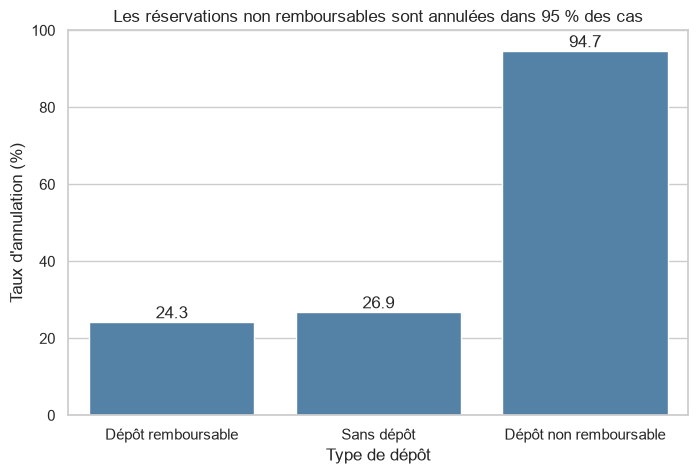

In [6]:
taux_depot_trie = (hotels.groupby("deposit_type")["is_canceled"].mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=taux_depot_trie.index, y=taux_depot_trie.values, color="steelblue", ax=ax)
ax.set_title("Les réservations non remboursables sont annulées dans 95 % des cas")
ax.set_xlabel("Type de dépôt")
ax.set_ylabel("Taux d'annulation (%)")
ax.set_ylim(0, 100)
ax.bar_label(ax.containers[0], fmt="%.1f")
fig.savefig("../figures/graphique_1_annulation_depot.png", dpi=150, bbox_inches="tight")
plt.show()

**Type de graphique : barres.** On compare un taux entre trois catégories de dépôt, triées de la plus basse à la plus haute.

**Réponse à la question 1 :** 27.7 % des réservations sont annulées. L'hôtel de ville annule davantage (30.2 %) que l'hôtel de villégiature (23.7 %). Le type de dépôt pèse encore plus : 94.7 % des réservations à dépôt non remboursable sont annulées, contre 26.9 % sans dépôt. Ce résultat est contre-intuitif et à interpréter avec prudence : ces réservations ne représentent que 1037 lignes (1,2 % du total) et le jeu de données ne dit pas pourquoi.

In [8]:
hotels["tranche_delai"] = pd.cut(
    hotels["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, 1000],
    labels=["0 à 7 jours", "8 à 30 jours", "31 à 90 jours",
            "91 à 180 jours", "181 à 365 jours", "plus de 365 jours"],
)

annulation_par_delai = hotels.groupby("tranche_delai", observed=True).agg(
    reservations=("is_canceled", "size"),
    taux_annulation=("is_canceled", "mean"),
)
annulation_par_delai["taux_annulation"] = (annulation_par_delai["taux_annulation"] * 100).round(1)
annulation_par_delai

,reservations,taux_annulation
tranche_delai,,
0 à 7 jours,17851,8.5
8 à 30 jours,16231,25.5
31 à 90 jours,22633,32.1
91 à 180 jours,18188,35.1
181 à 365 jours,11164,39.8
plus de 365 jours,561,41.0


In [9]:
hotels.groupby("is_canceled")["lead_time"].median()

is_canceled
0    38.0
1    80.0
Name: lead_time, dtype: float64

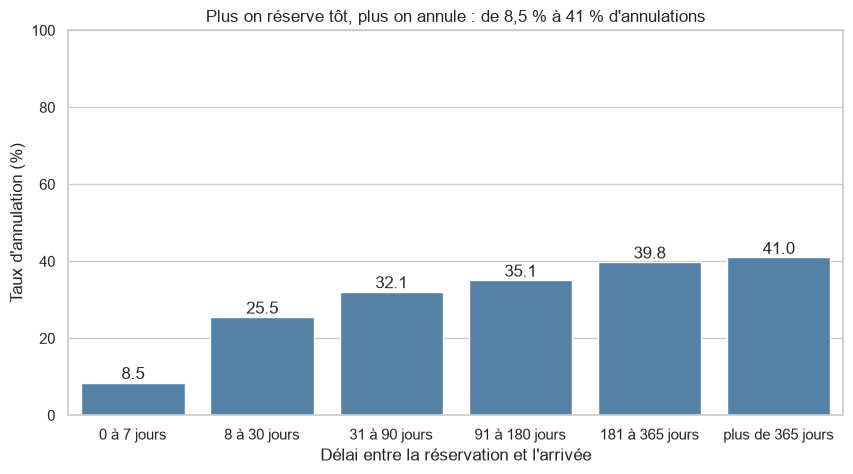

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    x=annulation_par_delai.index.astype(str),
    y=annulation_par_delai["taux_annulation"],
    color="steelblue", ax=ax,
)
ax.set_title("Plus on réserve tôt, plus on annule : de 8,5 % à 41 % d'annulations")
ax.set_xlabel("Délai entre la réservation et l'arrivée")
ax.set_ylabel("Taux d'annulation (%)")
ax.set_ylim(0, 100)
ax.bar_label(ax.containers[0], fmt="%.1f")
fig.savefig("../figures/graphique_2_delai.png", dpi=150, bbox_inches="tight")
plt.show()

**Type de graphique : barres.** Les tranches de délai ont un ordre naturel (du plus court au plus long), qui est aussi l'ordre croissant des taux.

**Réponse à la question 2 :** Oui, le délai influence les annulations. Seulement 8.5 % des réservations faites moins d'une semaine avant l'arrivée sont annulées, contre 39.8 % à 41 % pour celles faites plus de six mois à l'avance. Le délai médian est de 38 jours pour les réservations maintenues et de 80 jours pour les annulées. Cette analyse montre un lien, pas une cause.

In [11]:
arrivees_par_mois = hotels.set_index("arrival_date").resample("MS").size()
arrivees_par_mois.name = "arrivees"
arrivees_par_mois.to_frame()

,arrivees
arrival_date,
2015-07-01,1652
2015-08-01,2428
2015-09-01,2823
2015-10-01,2661
2015-11-01,1636
2015-12-01,1940
2016-01-01,1823
2016-02-01,2771
2016-03-01,3791


In [12]:
noms_mois = ["janvier", "février", "mars", "avril", "mai", "juin",
             "juillet", "août", "septembre", "octobre", "novembre", "décembre"]

classement_2016 = arrivees_par_mois.loc["2016"].sort_values(ascending=False)
classement_2016.index = [noms_mois[date.month - 1] for date in classement_2016.index]
classement_2016

août         4394
octobre      4180
septembre    3835
juillet      3818
mars         3791
avril        3741
mai          3739
juin         3487
novembre     3278
décembre     3104
février      2771
janvier      1823
Name: arrivees, dtype: int64

In [13]:
print(f"Mois le plus chargé : {arrivees_par_mois.idxmax():%Y-%m} ({arrivees_par_mois.max()} arrivées)")
print(f"Mois le plus calme : {arrivees_par_mois.idxmin():%Y-%m} ({arrivees_par_mois.min()} arrivées)")

Mois le plus chargé : 2017-05 (4556 arrivées)
Mois le plus calme : 2015-11 (1636 arrivées)


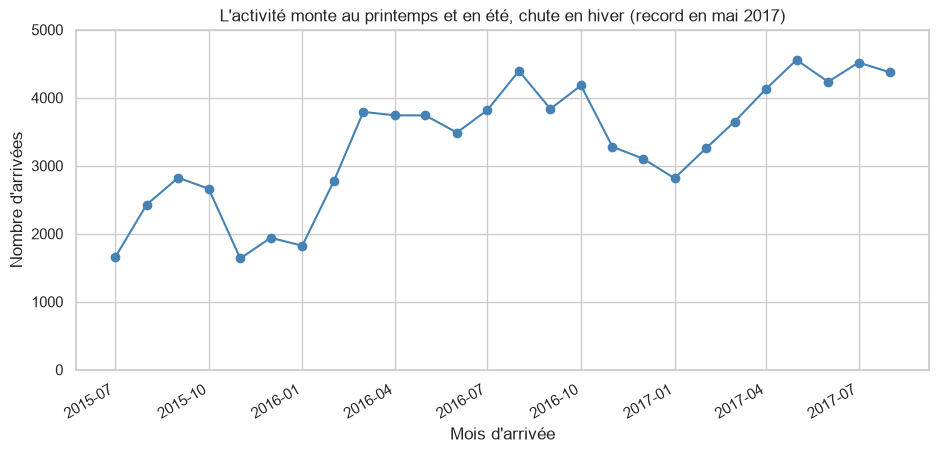

In [14]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(arrivees_par_mois.index, arrivees_par_mois.values, marker="o", color="steelblue")
ax.set_title("L'activité monte au printemps et en été, chute en hiver (record en mai 2017)")
ax.set_xlabel("Mois d'arrivée")
ax.set_ylabel("Nombre d'arrivées")
ax.set_ylim(0, 5000)
fig.autofmt_xdate()
fig.savefig("../figures/graphique_3_arrivees_par_mois.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
hotels_payants = hotels[hotels["adr"] > 0].copy()
hotels_payants["mois_arrivee"] = hotels_payants["arrival_date"].dt.month

saisons = {12: "Hiver", 1: "Hiver", 2: "Hiver",
           3: "Printemps", 4: "Printemps", 5: "Printemps",
           6: "Été", 7: "Été", 8: "Été",
           9: "Automne", 10: "Automne", 11: "Automne"}
hotels_payants["saison"] = hotels_payants["mois_arrivee"].map(saisons)
ordre_saisons = ["Hiver", "Printemps", "Été", "Automne"]

print(f"Séjours avec un prix : {len(hotels_payants)} sur {len(hotels)}")

Séjours avec un prix : 85576 sur 86628


In [16]:
prix_par_saison = hotels_payants.groupby("saison")["adr"].agg(
    sejours="size", prix_moyen="mean",
).round(1).loc[ordre_saisons]
prix_par_saison

,sejours,prix_moyen
saison,,
Hiver,15464,77.7
Printemps,23358,100.8
Été,28647,139.3
Automne,18107,96.0


In [17]:
prix_hotel_saison = pd.pivot_table(
    hotels_payants, values="adr", index="hotel", columns="saison", aggfunc="mean",
)[ordre_saisons].round(1)
prix_hotel_saison

saison,Hiver,Printemps,Été,Automne
hotel,,,,
Hôtel de ville,91.5,115.3,125.1,110.0
Hôtel de villégiature,58.1,74.4,160.3,74.0


In [18]:
prix_par_mois = hotels_payants.groupby("mois_arrivee")["adr"].mean().round(1)
prix_par_mois

mois_arrivee
1      71.9
2      76.5
3      82.5
4     105.2
5     113.1
6     121.5
7     137.7
8     153.0
9     114.7
10     92.9
11     74.9
12     84.6
Name: adr, dtype: float64

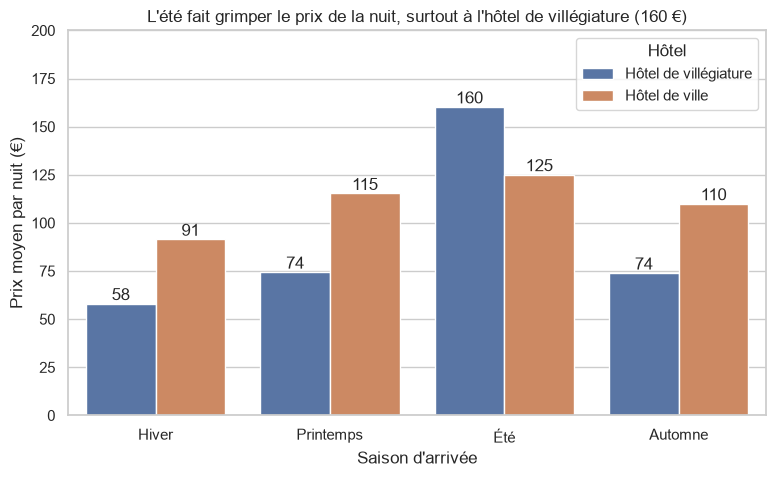

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=hotels_payants, x="saison", y="adr", hue="hotel",
    order=ordre_saisons, errorbar=None, ax=ax,
)
ax.set_title("L'été fait grimper le prix de la nuit, surtout à l'hôtel de villégiature (160 €)")
ax.set_xlabel("Saison d'arrivée")
ax.set_ylabel("Prix moyen par nuit (€)")
ax.set_ylim(0, 200)
ax.legend(title="Hôtel")
for barres in ax.containers:
    ax.bar_label(barres, fmt="%.0f")
fig.savefig("../figures/graphique_4_prix_par_saison.png", dpi=150, bbox_inches="tight")
plt.show()

**Graphique 3 : courbe.** Elle convient à une évolution dans le temps, mois après mois.
**Graphique 4 : barres groupées.** Elles comparent un prix moyen entre quatre saisons, avec une couleur par hôtel (la couleur porte un sens). Les saisons suivent l'ordre du calendrier plutôt qu'un tri par valeur.

**Réponse à la question 3 :** Le printemps et l'été sont les périodes les plus chargées, l'hiver la plus calme. Sur 2016, la seule année complète, août est le mois le plus chargé (4394 arrivées) et janvier le plus calme (1823). Le record de la série est mai 2017 (4556) et le creux novembre 2015 (1636). Le prix moyen par nuit suit la même saisonnalité : 77.7 en hiver, 100.8 au printemps, 139.3 en été et 96.0 en automne. L'effet est bien plus fort à l'hôtel de villégiature (58.1 en hiver, 160.3 en été, soit presque trois fois plus) qu'à l'hôtel de ville (91.5 en hiver, 125.1 en été). Le mois le plus cher est août (153.0), le moins cher janvier (71.9).

**Limites :** le jeu de données ne précise pas la devise (supposée en euros) et le volume d'arrivées est plus faible au début de la période (été 2015), ce qui rend les comparaisons d'une année à l'autre moins fiables. Les 1052 séjours à prix 0 sont exclus des moyennes de prix.

In [20]:
hotels["country"].value_counts().head(22)

country
PRT        26857
GBR        10399
FRA         8813
ESP         7228
DEU         5385
ITA         3056
IRL         3014
BEL         2078
BRA         1988
NLD         1908
USA         1867
CHE         1564
CN          1092
AUT          946
SWE          832
CHN          813
POL          761
RUS          556
NOR          514
ROU          458
Inconnu      442
FIN          421
Name: count, dtype: int64

In [21]:
table_pays = pd.DataFrame({
    "country": ["PRT", "GBR", "FRA", "ESP", "DEU", "ITA", "IRL", "BEL", "BRA", "NLD", "USA",
                "CHE", "CN", "CHN", "AUT", "SWE", "POL", "RUS", "NOR", "ROU", "Inconnu"],
    "pays": ["Portugal", "Royaume-Uni", "France", "Espagne", "Allemagne", "Italie", "Irlande",
             "Belgique", "Brésil", "Pays-Bas", "États-Unis", "Suisse", "Chine", "Chine",
             "Autriche", "Suède", "Pologne", "Russie", "Norvège", "Roumanie", "Pays inconnu"],
})
table_pays

,country,pays
0,PRT,Portugal
1,GBR,Royaume-Uni
2,FRA,France
3,ESP,Espagne
4,DEU,Allemagne
5,ITA,Italie
6,IRL,Irlande
7,BEL,Belgique
8,BRA,Brésil
9,NLD,Pays-Bas


In [22]:
nb_avant = len(hotels)
hotels_pays = hotels.merge(table_pays, on="country", how="left", validate="many_to_one")
assert len(hotels_pays) == nb_avant

print(f"Lignes avant : {nb_avant} / après : {len(hotels_pays)}")
print(f"Lignes sans correspondance : {hotels_pays['pays'].isna().sum()}")
print(f"Codes pays concernés : {hotels_pays.loc[hotels_pays['pays'].isna(), 'country'].nunique()}")

Lignes avant : 86628 / après : 86628
Lignes sans correspondance : 6057
Codes pays concernés : 157


In [23]:
hotels_pays["pays"] = hotels_pays["pays"].fillna("Autres pays")
hotels_pays["pays"].value_counts()

pays
Portugal        26857
Royaume-Uni     10399
France           8813
Espagne          7228
Autres pays      6057
Allemagne        5385
Italie           3056
Irlande          3014
Belgique         2078
Brésil           1988
Pays-Bas         1908
Chine            1905
États-Unis       1867
Suisse           1564
Autriche          946
Suède             832
Pologne           761
Russie            556
Norvège           514
Roumanie          458
Pays inconnu      442
Name: count, dtype: int64

In [24]:
origine = hotels_pays.groupby("pays").agg(
    reservations=("is_canceled", "size"),
    taux_annulation=("is_canceled", "mean"),
)
origine["part_des_reservations"] = (origine["reservations"] / len(hotels_pays) * 100).round(1)
origine["taux_annulation"] = (origine["taux_annulation"] * 100).round(1)
origine.sort_values("reservations", ascending=False)

,reservations,taux_annulation,part_des_reservations
pays,,,
Portugal,26857,36.4,31.0
Royaume-Uni,10399,19.1,12.0
France,8813,19.6,10.2
Espagne,7228,25.7,8.3
Autres pays,6057,31.0,7.0
Allemagne,5385,19.6,6.2
Italie,3056,35.1,3.5
Irlande,3014,22.2,3.5
Belgique,2078,19.7,2.4


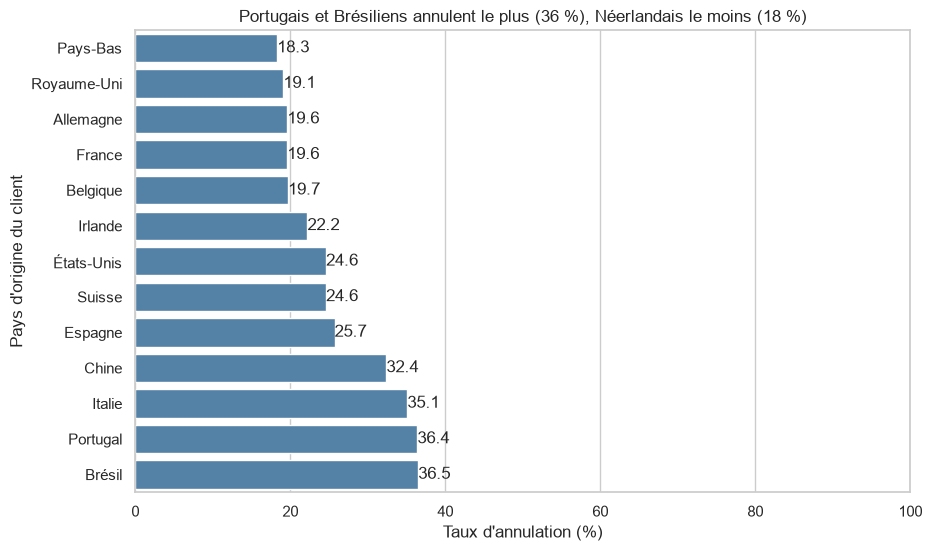

In [25]:
pays_principaux = origine[
    (origine["reservations"] >= 1000) & (~origine.index.isin(["Autres pays", "Pays inconnu"]))
].sort_values("taux_annulation")

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=pays_principaux["taux_annulation"], y=pays_principaux.index, color="steelblue", ax=ax)
ax.set_title("Portugais et Brésiliens annulent le plus (36 %), Néerlandais le moins (18 %)")
ax.set_xlabel("Taux d'annulation (%)")
ax.set_ylabel("Pays d'origine du client")
ax.set_xlim(0, 100)
ax.bar_label(ax.containers[0], fmt="%.1f")
fig.savefig("../figures/graphique_5_annulation_par_pays.png", dpi=150, bbox_inches="tight")
plt.show()

### Décision 10 : jointure avec une table de pays

| Quoi | Pourquoi | Lignes |
|---|---|---|
| jointure `left` avec une table de 21 codes pays (`validate="many_to_one"`) | donner un nom lisible aux codes pays. La jointure `left` garde toutes les réservations : 86628 avant, 86628 après | 86628 |
| codes `CN` et `CHN` regroupés sous « Chine » | deux codes pour le même pays dans les données | 1905 |
| 157 codes rares regroupés en « Autres pays » | aucune correspondance dans la table, trop rares pour être analysés un par un | 6057 |

**Graphique 5 : barres horizontales triées.** On compare un taux entre pays, et les noms de pays sont plus lisibles à l'horizontale.

**Réponse à la question 4 :** Les clients viennent surtout du Portugal (31.0 % des réservations), puis du Royaume-Uni (12.0 %), de la France (10.2 %), de l'Espagne (8.3 %) et de l'Allemagne (6.2 %). Ces 5 pays représentent 67.7 % des réservations. Les pays qui annulent le plus sont le Brésil (36.5 %), le Portugal (36.4 %), l'Italie (35.1 %) et la Chine (32.4 %). Ceux qui annulent le moins sont les Pays-Bas (18.3 %), le Royaume-Uni (19.1 %), l'Allemagne et la France (19.6 %). Les clients portugais, les plus nombreux, annulent nettement plus que les autres (36.4 % contre 23.8 % pour les autres pays réunis).

**Limites :** « Autres pays » regroupe 157 codes (7.0 % des réservations) et 442 réservations n'ont pas de pays. Le graphique ne montre que les 13 pays à plus de 1000 réservations (87.8 % du total). Le jeu de données n'explique pas pourquoi un pays annule plus qu'un autre.

In [26]:
hotels["nuits"] = hotels["stays_in_weekend_nights"] + hotels["stays_in_week_nights"]

sejours_payes = hotels[(hotels["is_canceled"] == 0) & (hotels["adr"] > 0)].copy()
sejours_payes["chiffre_affaires"] = sejours_payes["adr"] * sejours_payes["nuits"]

total_ca = f"{sejours_payes['chiffre_affaires'].sum():,.0f}".replace(",", " ")
print(f"Séjours effectifs et payants : {len(sejours_payes)} sur {len(hotels)}")
print(f"Chiffre d'affaires estimé total : {total_ca}")

Séjours effectifs et payants : 61739 sur 86628
Chiffre d'affaires estimé total : 22 967 027


In [27]:
rapport_par_segment = sejours_payes.groupby("market_segment").agg(
    sejours=("chiffre_affaires", "size"),
    nuits=("nuits", "sum"),
    prix_moyen=("adr", "mean"),
    chiffre_affaires=("chiffre_affaires", "sum"),
)
rapport_par_segment["part_du_ca"] = (
    rapport_par_segment["chiffre_affaires"] / rapport_par_segment["chiffre_affaires"].sum() * 100
).round(1)
rapport_par_segment[["prix_moyen", "chiffre_affaires"]] = rapport_par_segment[["prix_moyen", "chiffre_affaires"]].round(1)
rapport_par_segment.sort_values("chiffre_affaires", ascending=False)

,sejours,nuits,prix_moyen,chiffre_affaires,part_du_ca
market_segment,,,,,
Online TA,33016,111341,115.8,12965977.6,56.5
Offline TA/TO,11595,55816,81.6,4595456.1,20.0
Direct,9861,30900,117.2,3925328.5,17.1
Groups,3405,12172,78.8,922901.0,4.0
Corporate,3627,7115,67.9,483590.8,2.1
Aviation,178,672,102.3,68968.4,0.3
Complementary,57,143,34.8,4804.5,0.0


In [28]:
annulation_par_segment = hotels.groupby("market_segment").agg(
    reservations=("is_canceled", "size"),
    taux_annulation=("is_canceled", "mean"),
)
annulation_par_segment["taux_annulation"] = (annulation_par_segment["taux_annulation"] * 100).round(1)
annulation_par_segment.sort_values("taux_annulation")

,reservations,taux_annulation
market_segment,,
Complementary,682,12.2
Corporate,4151,12.2
Direct,11652,14.9
Offline TA/TO,13746,14.9
Aviation,222,19.8
Groups,4891,27.2
Online TA,51282,35.5
Inconnu,2,100.0


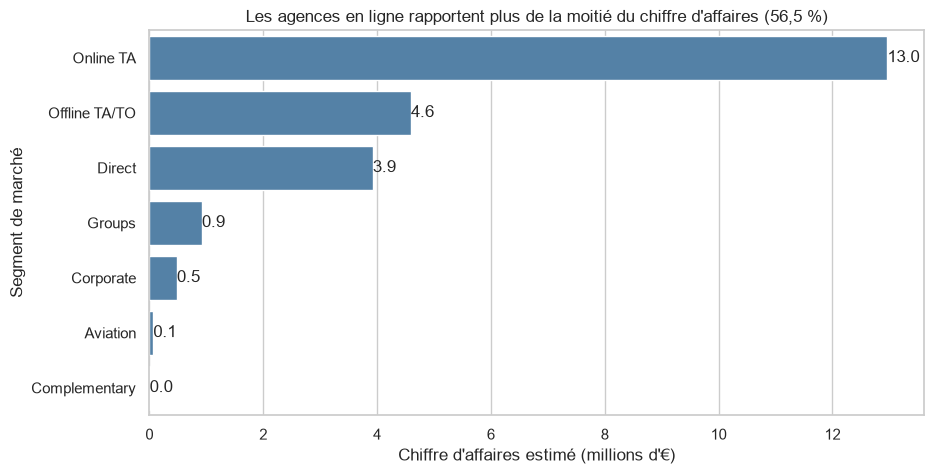

In [29]:
ca_par_segment = rapport_par_segment.sort_values("chiffre_affaires", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    x=ca_par_segment["chiffre_affaires"] / 1_000_000,
    y=ca_par_segment.index,
    color="steelblue", ax=ax,
)
ax.set_title("Les agences en ligne rapportent plus de la moitié du chiffre d'affaires (56,5 %)")
ax.set_xlabel("Chiffre d'affaires estimé (millions d'€)")
ax.set_ylabel("Segment de marché")
ax.bar_label(ax.containers[0], fmt="%.1f")
fig.savefig("../figures/graphique_6_ca_par_segment.png", dpi=150, bbox_inches="tight")
plt.show()

**Graphique 6 : barres horizontales triées.** On compare un total entre sept segments, et les noms de segments sont plus lisibles à l'horizontale.

**Réponse à la question 5 :** Le segment Online TA (agences en ligne) rapporte le plus : environ 13.0 millions sur 23.0 millions de chiffre d'affaires estimé, soit 56.5 %. Viennent ensuite Offline TA/TO (4.6 millions, 20.0 %) et Direct (3.9 millions, 17.1 %). À eux trois, ces segments font 93.6 % du chiffre d'affaires. Les agences en ligne ont pourtant le taux d'annulation le plus élevé (35.5 %), mais leur volume (33016 séjours effectifs) compense. Le segment Direct a le prix moyen par nuit le plus haut (117.2) et seulement 14.9 % d'annulations. Le segment Corporate annule peu (12.2 %) mais pèse seulement 2.1 % du chiffre d'affaires.

**Limites :** le chiffre d'affaires est estimé (prix moyen par nuit × nombre de nuits) pour les séjours non annulés et payants ; 906 séjours à prix 0 sont exclus. Le jeu de données ne précise pas la devise (supposée en euros) ni les commissions versées aux agences : le revenu net des segments Online TA et Offline TA/TO est donc probablement plus faible que ce chiffre brut.

## Synthèse : une réponse par question

| Question | Réponse |
|---|---|
| 1. Taux d'annulation, selon l'hôtel et le dépôt | 27.7 % des réservations sont annulées : 30.2 % à l'hôtel de ville contre 23.7 % à l'hôtel de villégiature. Les réservations à dépôt non remboursable sont annulées dans 94.7 % des cas, un résultat contre-intuitif qui ne porte que sur 1037 réservations |
| 2. Le délai de réservation | Plus on réserve tôt, plus on annule : 8.5 % d'annulations à moins d'une semaine, 41.0 % à plus d'un an. Délai médian de 38 jours pour les réservations maintenues, 80 pour les annulées |
| 3. Mois chargés et prix par saison | Le printemps et l'été sont les plus chargés (août en tête sur 2016, record en mai 2017), l'hiver le plus calme. Le prix moyen par nuit passe de 77.7 en hiver à 139.3 en été, et de 58.1 à 160.3 à l'hôtel de villégiature |
| 4. Origine des clients et pays qui annulent | 31.0 % des réservations viennent du Portugal. Le Brésil (36.5 %) et le Portugal (36.4 %) annulent le plus, les Pays-Bas (18.3 %) le moins |
| 5. Segment qui rapporte le plus | Les agences en ligne (Online TA) rapportent 56.5 % du chiffre d'affaires estimé, malgré le taux d'annulation le plus élevé (35.5 %) |

## Limites de l'analyse

- **Doublons** : 31994 lignes identiques supprimées faute d'identifiant de réservation. Une partie (surtout des groupes) pourrait être de vraies réservations : le taux d'annulation passe de 37.0 % avec les doublons à 27.5 % sans eux.
- **Corrélation, pas cause** : les analyses montrent des liens (délai, pays, dépôt), jamais des causes.
- **Période** : juillet 2015 à août 2017 seulement. Les mois de juillet et août apparaissent 3 fois, les autres 2 fois, et le volume est plus faible en 2015.
- **Prix** : la devise n'est pas précisée (supposée en euros). Les 1052 séjours à prix 0 sont exclus des moyennes de prix.
- **Chiffre d'affaires** : estimé (prix moyen par nuit × nombre de nuits) sur les séjours non annulés. Les commissions des agences ne sont pas connues : le revenu net des agences est probablement plus faible.
- **Pays** : 157 codes rares sont regroupés en « Autres pays » (7.0 % des réservations).